# Compute abundance change for each allele

This script takes in the single-cell FACS data as input, applies various filtering criteria, and then produces a z-score for the abundance of each allele relative to the reference on the same plate.

In [35]:
import pandas as pd
import numpy as np
from random import choice

import process_dualipa as proc

In [2]:
dualipa_inputs = "../1_inputs"
dualipa_outputs = "../3_outputs"

n_cell_threshold = 800
wt_gfp_threshold = 100

In [37]:
# Read in single-cell measurements
pDEST_DUAL_df = pd.read_parquet(f"{dualipa_outputs}/facs_single_cell.parquet")

# Filter to only keep wells with more than 800 cells
pDEST_DUAL_df = pDEST_DUAL_df[pDEST_DUAL_df['n_cells'] > n_cell_threshold]

In [38]:
# get the mean and median measurements per well
keep_cols = ['symbol', 'node_type', 'nt_change','aa_change', 'pla', 'well', 'coordinates', 'n_cells', 'orf_id', 'mut_id', 'valid_well']

pDEST_DUAL_avg_df = pDEST_DUAL_df[keep_cols + ['avg_gfp', 'avg_mcherry','avg_GFP_mCherry_ratio']].drop_duplicates()
pDEST_DUAL_median_df = pDEST_DUAL_df[keep_cols + ['median_gfp', 'median_mcherry','median_GFP_mCherry_ratio']].drop_duplicates()

In [39]:
# _d objects: mean or median GFP_mCherry ratio of each unique (wt orf, plate) combination
# _l objects: list of WT:WT abundances (GFP:mCherry ratios) to estimate assay variability
wt_avg_d, wt_ratio_l = proc.get_wt_variability_d(pDEST_DUAL_avg_df, pDEST_DUAL_df)
wt_median_d, wt_ratio_l_median = proc.get_wt_variability_d_median(pDEST_DUAL_median_df, pDEST_DUAL_df)

In [40]:
# Must be two WT replicates on same plate to compute the ratio, otherwise we return a NaN
pDEST_DUAL_avg_allele_df = proc.get_pDEST_DUAL_avg_allele_df(pDEST_DUAL_avg_df, wt_avg_d, wt_ratio_l)
pDEST_DUAL_median_allele_df = proc.get_pDEST_DUAL_median_allele_df(pDEST_DUAL_median_df, wt_median_d, wt_ratio_l_median)

In [42]:
# write out files
pDEST_DUAL_avg_allele_df.to_csv(f'{dualipa_outputs}/DUALIPA_mean_zscore.tsv', sep='\t', index=False)
pDEST_DUAL_median_allele_df.to_csv(f'{dualipa_outputs}/DUALIPA_median_zscore.tsv', sep='\t', index=False)

## Compare DUAL-IPA and imaging abundance changes

In [ ]:
import polars as pl
import matplotlib.pyplot as plt

dualipa = pl.DataFrame(pDEST_DUAL_avg_allele_df).with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("Variant")
)


dualipa = dualipa.select(["Variant", "zscore_log2", "zscore", "avg_gfp"]).rename({
    "zscore_log2": "dualipa_zscore_log2",
    "zscore": "dualipa_zscore"
})

# get imaging abundance measures
imaging = pl.read_csv("../../imaging/3_outputs/abundance/abundance_ttest_stats.csv").select([
    "Variant", "U2OS_t"
]).rename({
    "U2OS_t": "imaging_zscore"
}).filter(pl.col("imaging_zscore") > -100) # there is one major outlier

abun_df = dualipa.join(imaging, on="Variant").to_pandas()
print(abun_df.shape)


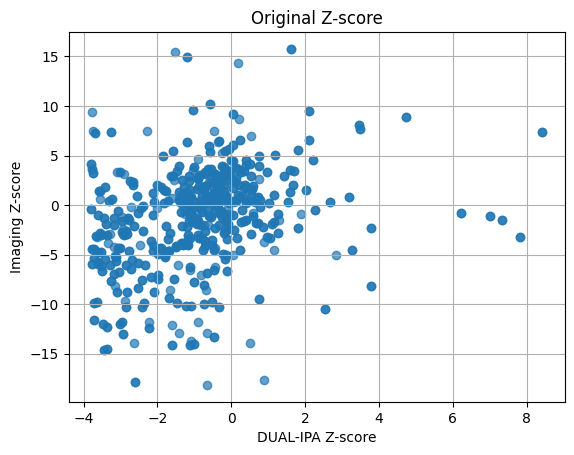

In [69]:
plt.scatter(abun_df['dualipa_zscore'], abun_df['imaging_zscore'], alpha=0.7)
plt.ylabel('Imaging Z-score')
plt.xlabel('DUAL-IPA Z-score')
plt.title('Original Z-score')
plt.grid(True)
plt.show()

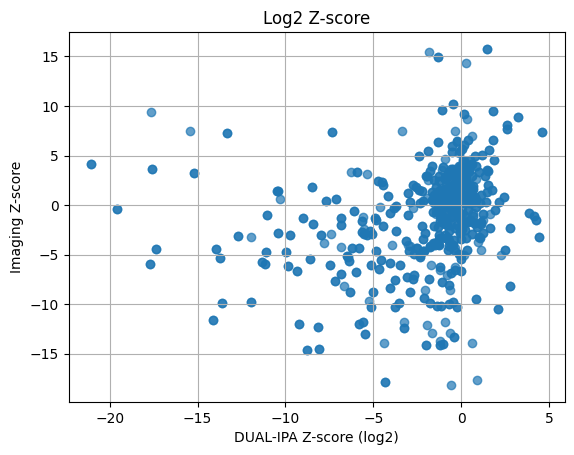

In [71]:
plt.scatter(abun_df['dualipa_zscore_log2'], abun_df['imaging_zscore'], alpha=0.7)
plt.ylabel('Imaging Z-score')
plt.xlabel('DUAL-IPA Z-score (log2)')
plt.title('Log2 Z-score')
plt.grid(True)
plt.show()